# **Hoja de trabajo 2 - Transformers y mecanismos de atención**

Adriana Palacios - 23044  
CC3092 - Deep Learning y Sistemas Inteligentes

## **Setup**

In [1]:
%pip install -q torch transformers numpy pandas matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import random

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn.functional as F
from transformers import AutoModel, AutoTokenizer

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)
torch.manual_seed(SEMILLA)
DISPOSITIVO = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print("PyTorch:", torch.__version__, "| Dispositivo:", DISPOSITIVO)

PyTorch: 2.13.0 | Dispositivo: mps


## **2. Investigación: de las RNN a la atención**

**¿Cuál era el cuello de botella de seq2seq?** En el encoder-decoder recurrente básico, el encoder debía comprimir toda la oración de entrada en un único vector de estado. El decoder recibía ese resumen para producir cada palabra. Cuanto más larga era la entrada, más información debía caber en el mismo vector y más pasos separaban a las primeras palabras de la salida. La atención de Bahdanau cambió esto: en cada paso de decodificación calcula pesos sobre *todos* los estados del encoder y forma un vector de contexto distinto. Así puede consultar la parte relevante de la entrada en vez de depender siempre del mismo resumen [1].

**Atención aditiva y multiplicativa.** Bahdanau mide la relación entre estados con una pequeña red aprendida. Luong propone calcularla con productos punto, directamente o con una transformación aprendida [2]. La multiplicativa suele aprovechar mejor el hardware actual porque los productos punto de muchas consultas y llaves se agrupan en multiplicaciones de matrices. La aditiva añade proyecciones y una no linealidad por par; puede ser útil cuando las dimensiones o la forma de la compatibilidad requieren más flexibilidad.

**Q, K y V como búsqueda suave.** Imagino las llaves como etiquetas de un diccionario y los valores como la información guardada. La consulta se compara con todas las llaves; la softmax convierte las similitudes en pesos y devuelve una mezcla de valores, no una sola entrada. En self-attention, Q, K y V salen de proyecciones aprendidas de la misma secuencia. En cross-attention, las consultas salen de la secuencia que consulta (por ejemplo, el decoder) y las llaves y valores de la secuencia consultada (por ejemplo, la salida del encoder) [3].

**¿Qué cambia al quitar la recurrencia?** Los tokens de una capa pueden procesarse en paralelo, y dos posiciones cualesquiera pueden intercambiar información en una capa de atención global. Esto acorta el camino de dependencias y evita el producto de gradientes a través de muchos pasos recurrentes. No significa que desaparezcan todos los problemas de optimización ni que generar texto deje de ser secuencial: un decoder autorregresivo todavía produce un token a la vez [3].

## **3. Investigación: arquitectura Transformer**

### **Atención con producto punto escalado**

Primero se compara cada consulta con las llaves mediante productos punto. Esas similitudes se ajustan según el tamaño de las llaves, se convierten en pesos con softmax y se usan para combinar los valores. Si los componentes de la consulta y la llave son independientes, tienen media cero y varianza uno, la varianza del producto punto resulta igual al número de componentes. Por eso se divide entre la raíz cuadrada de ese tamaño: así los valores que entran a la softmax no crecen demasiado. Sin ese ajuste, la distribución puede concentrarse en muy pocas posiciones y producir gradientes pequeños [3].

### **Atención de múltiples cabezas**

Cada cabeza aprende una forma distinta de relacionar tokens. Una puede fijarse en posiciones cercanas y otra en tokens especiales o dependencias lejanas. Cuando el ancho total del modelo se reparte entre las cabezas, usar varias no aumenta necesariamente el número principal de parámetros frente a una sola cabeza del ancho completo: las proyecciones trabajan sobre el mismo ancho total. La cifra exacta puede variar por los sesgos y otros detalles de la implementación [3].

### **Posición de los tokens**

Sin información posicional, permutar la entrada permuta de la misma forma la salida de self-attention; el mecanismo no distingue por sí solo «el perro mordió al gato» de un orden distinto. El Transformer original suma a cada embedding valores de senos y cosenos calculados con distintas frecuencias; así cada posición recibe un patrón reconocible. Los embeddings aprendidos asignan vectores entrenables a posiciones y pueden adaptarse a los datos, pero dependen de las posiciones aprendidas. RoPE rota Q y K según su posición, de modo que su producto punto incorpora desplazamientos relativos; extrapolar a longitudes mayores sigue siendo un asunto empírico, no una garantía [3, 4].

### **Bloque completo**

La conexión residual suma la entrada a la salida de una subcapa y facilita que la información y el gradiente atraviesen varias capas. LayerNorm estabiliza la escala de las activaciones. Después de la atención, la red *feed-forward* aplica el mismo MLP a cada posición por separado (dos capas lineales con una no linealidad). En **Post-LN**, como en el artículo original, se suma la salida de la subcapa con su entrada y luego se normaliza. En **Pre-LN**, se normaliza la entrada antes de pasarla por la subcapa y después se suma la conexión residual. Pre-LN suele facilitar el entrenamiento de redes profundas, aunque la ubicación de la normalización cambia la dinámica del bloque [3].

### **Costo y alternativas**

Con atención estándar se comparan todos los pares de tokens, así que el trabajo y la matriz de pesos crecen de forma cuadrática al aumentar la longitud. FlashAttention conserva el resultado exacto y calcula por bloques para reducir el uso de memoria; aun así debe realizar las comparaciones entre posiciones. La atención por ventanas solo mira vecinos y reduce mucho el costo si la ventana se mantiene fija, pero pierde relaciones lejanas directas. La atención lineal cambia o aproxima el cálculo para acercarse a un crecimiento lineal, a cambio de no reproducir exactamente la atención estándar [5, 6].

### **Prueba breve en PyTorch**

In [3]:
q = torch.tensor([[[1., 0.], [0., 1.]]])
k = torch.tensor([[[1., 0.], [0., 1.], [1., 1.]]])
v = torch.tensor([[[1., 2.], [3., 4.], [5., 6.]]])

puntajes = q @ k.transpose(-2, -1) / math.sqrt(q.size(-1))
pesos = puntajes.softmax(dim=-1)
salida_manual = pesos @ v
salida_torch = F.scaled_dot_product_attention(q, k, v, dropout_p=0.0)

display(pd.DataFrame(pesos[0].numpy(), index=["q0", "q1"], columns=["k0", "k1", "k2"]).round(3))
print("Salida manual:\n", salida_manual)
print("Coincide con PyTorch:", torch.allclose(salida_manual, salida_torch, atol=1e-6))
assert torch.allclose(salida_manual, salida_torch, atol=1e-6)

,k0,k1,k2
q0,0.401,0.198,0.401
q1,0.198,0.401,0.401


Salida manual:
 tensor([[[3.0000, 4.0000],
         [3.4067, 4.4067]]])
Coincide con PyTorch: True


## **4. Investigación: atención en PyTorch y Hugging Face**

**F.scaled_dot_product_attention** recibe Q, K y V y calcula la salida de la atención. attn_mask restringe los pares permitidos o agrega sesgos; en una máscara booleana de esta función, True significa *participa*. dropout_p controla el dropout de los pesos y hay que ponerlo explícitamente en 0.0 al evaluar, porque la función lo aplica según ese valor. is_causal=True impide mirar posiciones futuras. scale permite cambiar el ajuste que, por defecto, divide las similitudes entre la raíz cuadrada del tamaño de cada llave [7].

**nn.MultiheadAttention** reúne proyecciones, varias cabezas y proyección de salida. embed_dim es la dimensión de entrada/salida, num_heads divide ese ancho, batch_first=True usa (batch, secuencia, características) y kdim/vdim permiten anchos distintos para K/V. En forward, key_padding_mask bloquea posiciones de relleno; attn_mask bloquea o modifica pares consulta-llave; need_weights=True solicita los pesos; average_attn_weights=False conserva las cabezas por separado. En las máscaras booleanas de esta clase, True significa *bloqueado*, al contrario que en la función anterior [8].

**nn.TransformerEncoderLayer** ofrece un bloque encoder completo: d_model fija el ancho, nhead las cabezas, dim_feedforward el ancho interno del MLP, dropout la regularización y norm_first=True selecciona Pre-LN. nn.Transformer.generate_square_subsequent_mask(sz) crea una máscara causal cuadrada para que cada posición solo use el pasado y su propia posición [9, 10].

**Hugging Face.** Al llamar un modelo con output_attentions=True, el resultado trae una tupla de matrices, una por capa. En self-attention, cada matriz tiene forma (batch, cabezas, longitud_consultas, longitud_llaves); en BERT y GPT-2 sin cache, las dos últimas dimensiones coinciden con la longitud de la entrada. Aquí uso implementación eager para poder inspeccionar esas matrices [11].

## **5. Ejercicios prácticos: visualización de atención**

In [3]:
tok_bert = AutoTokenizer.from_pretrained("bert-base-uncased")
bert = AutoModel.from_pretrained(
    "bert-base-uncased", output_attentions=True, attn_implementation="eager"
).to(DISPOSITIVO).eval()

tok_gpt2 = AutoTokenizer.from_pretrained("gpt2")
gpt2 = AutoModel.from_pretrained(
    "gpt2", output_attentions=True, attn_implementation="eager"
).to(DISPOSITIVO).eval()

print(f"BERT: {bert.config.num_hidden_layers} capas, {bert.config.num_attention_heads} cabezas")
print(f"GPT-2: {gpt2.config.n_layer} capas, {gpt2.config.n_head} cabezas")

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

...

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

BERT: 12 capas, 12 cabezas
GPT-2: 12 capas, 12 cabezas


In [4]:
def obtener_atenciones(modelo, tokenizador, texto):
    entradas = tokenizador(texto, return_tensors="pt", truncation=True)
    tokens = tokenizador.convert_ids_to_tokens(entradas["input_ids"][0])
    with torch.inference_mode():
        salida = modelo(**{k: val.to(DISPOSITIVO) for k, val in entradas.items()},
                        output_attentions=True, return_dict=True)
    atenciones = torch.stack([capa[0].detach().float().cpu() for capa in salida.attentions])
    assert atenciones.shape[-1] == atenciones.shape[-2] == len(tokens)
    assert torch.isfinite(atenciones).all()
    return tokens, atenciones  # capas x cabezas x consultas x llaves


def graficar_cabezas(tokens, atenciones, pares, titulo):
    fig, axes = plt.subplots(2, 2, figsize=(15, 12), constrained_layout=True)
    for ax, (capa, cabeza) in zip(axes.flat, pares):
        mapa = atenciones[capa, cabeza].numpy()
        imagen = ax.imshow(mapa, cmap="viridis", vmin=0, vmax=1, aspect="auto")
        ax.set_title(f"{titulo} - capa {capa + 1}, cabeza {cabeza + 1}")
        ax.set_xticks(range(len(tokens)), tokens, rotation=90)
        ax.set_yticks(range(len(tokens)), tokens)
        ax.set_xlabel("Token atendido (key)")
        ax.set_ylabel("Token que consulta (query)")
        fig.colorbar(imagen, ax=ax, fraction=0.045)
    plt.show()


oracion = "The tired animal crossed the street, and it finally rested."
tokens_bert, at_bert = obtener_atenciones(bert, tok_bert, oracion)
tokens_gpt2, at_gpt2 = obtener_atenciones(gpt2, tok_gpt2, oracion)
print("BERT:", tokens_bert, "| forma:", tuple(at_bert.shape))
print("GPT-2:", tokens_gpt2, "| forma:", tuple(at_gpt2.shape))

BERT: ['[CLS]', 'the', 'tired', 'animal', 'crossed', 'the', 'street', ',', 'and', 'it', 'finally', 'rested', '.', '[SEP]'] | forma: (12, 12, 14, 14)
GPT-2: ['The', 'Ġtired', 'Ġanimal', 'Ġcrossed', 'Ġthe', 'Ġstreet', ',', 'Ġand', 'Ġit', 'Ġfinally', 'Ġrested', '.'] | forma: (12, 12, 12, 12)


### **Cuatro cabezas de capas distintas**

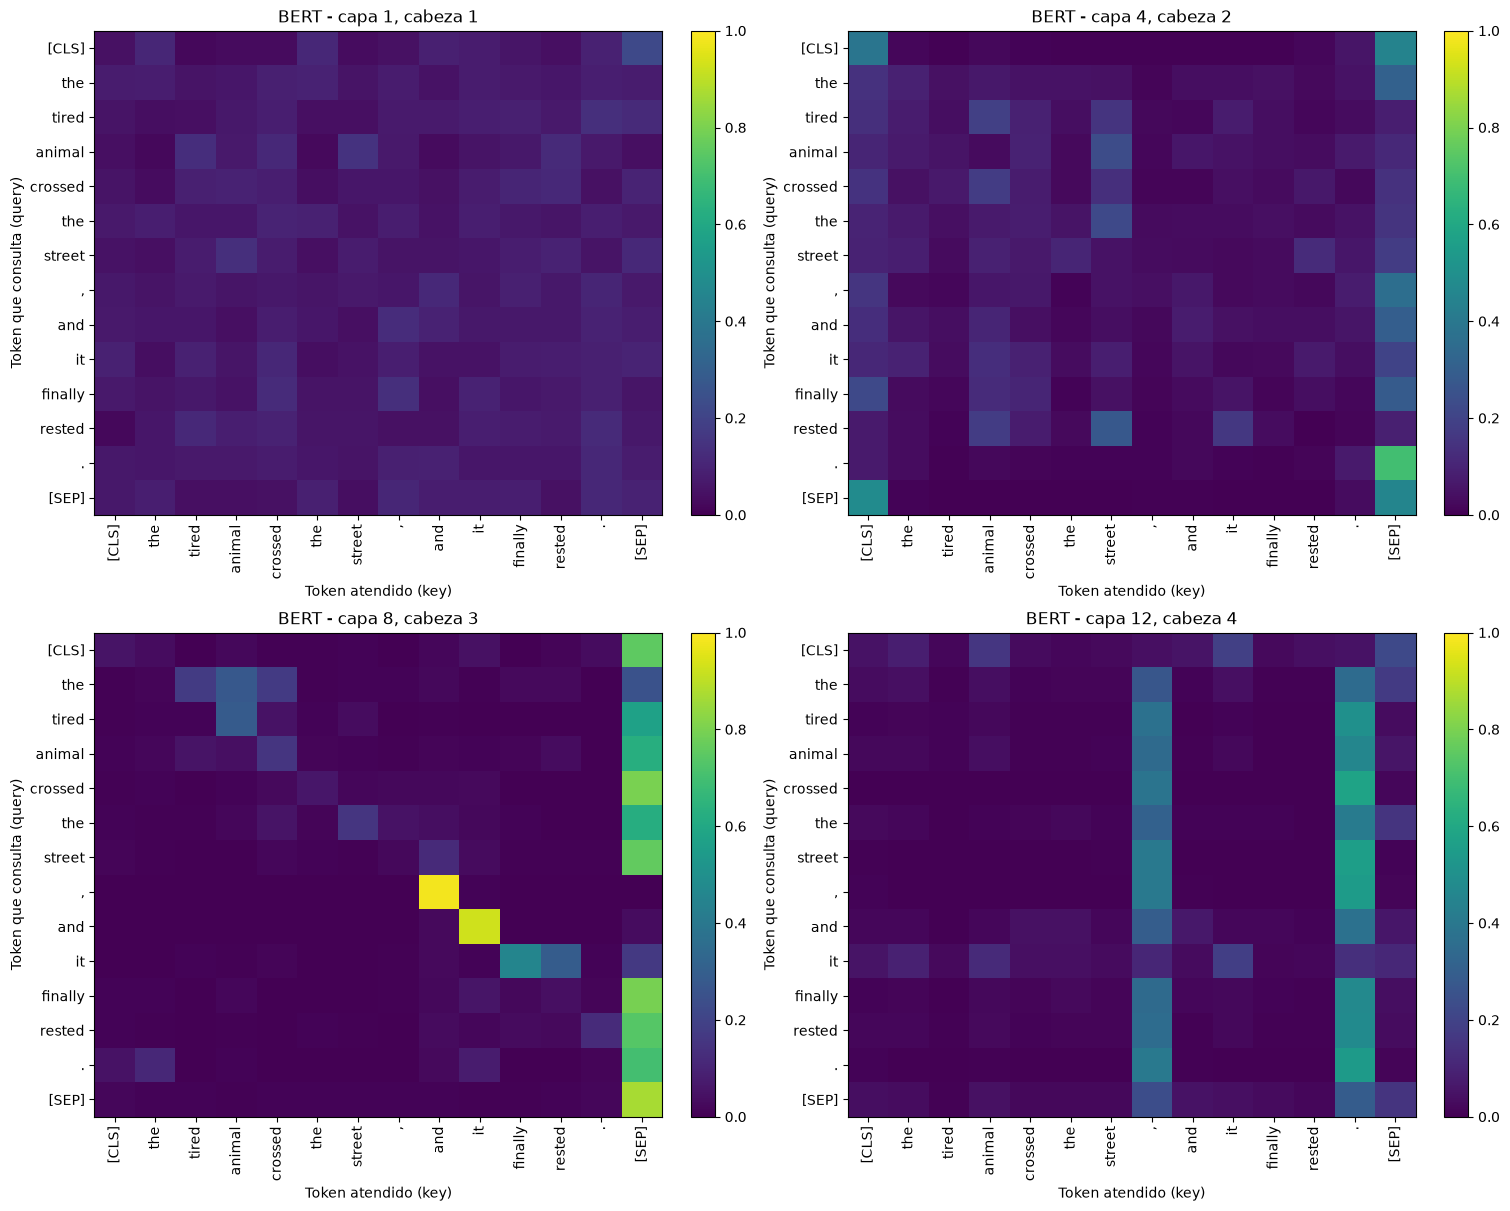

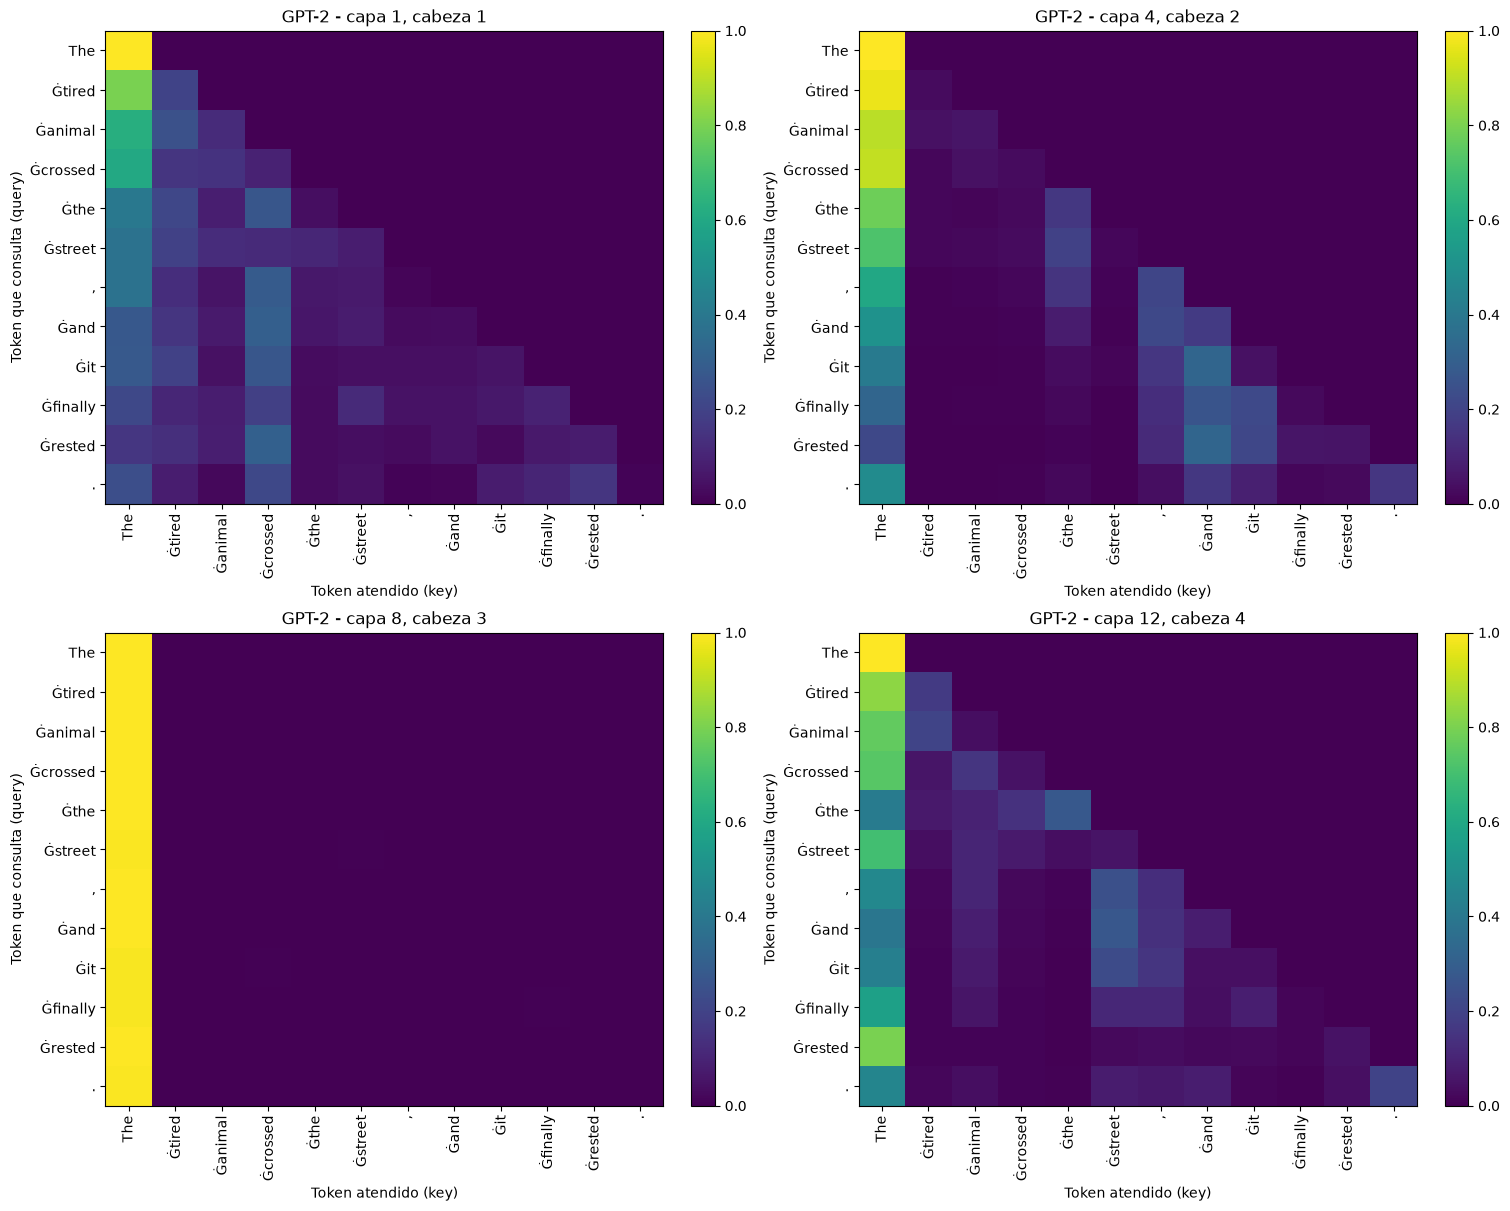

In [6]:
def seleccionar_pares(atenciones):
    n_capas, n_cabezas = atenciones.shape[:2]
    capas = np.linspace(0, n_capas - 1, 4, dtype=int)
    return [(int(capa), int(i % n_cabezas)) for i, capa in enumerate(capas)]

pares_bert = seleccionar_pares(at_bert)
pares_gpt2 = seleccionar_pares(at_gpt2)
graficar_cabezas(tokens_bert, at_bert, pares_bert, "BERT")
graficar_cabezas(tokens_gpt2, at_gpt2, pares_gpt2, "GPT-2")

### **Patrones que aparecen en las cabezas**

In [7]:
def resumen_patrones(tokens, atenciones, pares):
    n = len(tokens)
    filas = []
    especiales = [i for i, t in enumerate(tokens) if t in {"[CLS]", "[SEP]"}]
    puntuacion = [i for i, t in enumerate(tokens) if t in {".", ",", "!", "?", "Ġ.", "Ġ,"}]
    for capa, cabeza in pares:
        matriz = atenciones[capa, cabeza].numpy()
        filas.append({
            "capa": capa + 1, "cabeza": cabeza + 1,
            "mismo token": float(np.mean(np.diag(matriz))),
            "token anterior": float(np.mean([matriz[i, i-1] for i in range(1, n)])),
            "token siguiente": float(np.mean([matriz[i, i+1] for i in range(n-1)])),
            "[CLS]/[SEP]": float(matriz[:, especiales].sum(axis=1).mean()) if especiales else np.nan,
            "puntuación": float(matriz[:, puntuacion].sum(axis=1).mean()) if puntuacion else np.nan,
        })
    return pd.DataFrame(filas).round(3)

print("BERT")
display(resumen_patrones(tokens_bert, at_bert, pares_bert))
print("GPT-2")
display(resumen_patrones(tokens_gpt2, at_gpt2, pares_gpt2))

BERT


,capa,cabeza,mismo token,token anterior,token siguiente,[CLS]/[SEP],puntuación
0,1,1,0.074,0.082,0.076,0.150,0.169
1,4,2,0.101,0.068,0.116,0.440,0.065
2,8,3,0.081,0.021,0.317,0.563,0.026
3,12,4,0.109,0.055,0.082,0.098,0.717


GPT-2


,capa,cabeza,mismo token,token anterior,token siguiente,[CLS]/[SEP],puntuación
0,1,1,0.152,0.181,0.0,NaN,0.015
1,4,2,0.163,0.194,0.0,NaN,0.086
2,8,3,0.085,0.091,0.0,NaN,0.000
3,12,4,0.175,0.175,0.0,NaN,0.070


En BERT se ven patrones distintos entre las cabezas. La de la capa 8, cabeza 3, presta bastante atención al token siguiente y a [CLS]/[SEP]. En cambio, la de la capa 12, cabeza 4, mira sobre todo la puntuación. En GPT-2 la atención al token siguiente es cero, como se esperaría de su máscara.

### **BERT: «it» frente a «animal» y «street»**

In [8]:
texto_tired = "The animal didn't cross the street because it was too tired."
texto_wide = "The animal didn't cross the street because it was too wide."
tokens_tired, at_tired = obtener_atenciones(bert, tok_bert, texto_tired)
tokens_wide, at_wide = obtener_atenciones(bert, tok_bert, texto_wide)

def posiciones_referencia(tokens):
    return {palabra: tokens.index(palabra) for palabra in ("animal", "street", "it")}

pos_t = posiciones_referencia(tokens_tired)
pos_w = posiciones_referencia(tokens_wide)
filas = []
for capa in range(at_tired.shape[0]):
    for cabeza in range(at_tired.shape[1]):
        ta = float(at_tired[capa, cabeza, pos_t["it"], pos_t["animal"]])
        ts = float(at_tired[capa, cabeza, pos_t["it"], pos_t["street"]])
        wa = float(at_wide[capa, cabeza, pos_w["it"], pos_w["animal"]])
        ws = float(at_wide[capa, cabeza, pos_w["it"], pos_w["street"]])
        filas.append({"capa": capa + 1, "cabeza": cabeza + 1,
                      "tired→animal": ta, "tired→street": ts,
                      "wide→animal": wa, "wide→street": ws,
                      "cambio buscado": ta > ts and ws > wa,
                      "margen conjunto": (ta - ts) + (ws - wa)})

contraste = pd.DataFrame(filas)
coincidencias = contraste[contraste["cambio buscado"]].sort_values("margen conjunto", ascending=False)
print("Tokens tired:", tokens_tired)
print("Tokens wide: ", tokens_wide)
print(f"Cabezas que cumplen ambos criterios: {len(coincidencias)} de {len(contraste)}")
display((coincidencias.head(10) if len(coincidencias) else contraste.nlargest(10, "margen conjunto")).round(4))

Tokens tired: ['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'tired', '.', '[SEP]']
Tokens wide:  ['[CLS]', 'the', 'animal', 'didn', "'", 't', 'cross', 'the', 'street', 'because', 'it', 'was', 'too', 'wide', '.', '[SEP]']
Cabezas que cumplen ambos criterios: 22 de 144


,capa,cabeza,tired→animal,tired→street,wide→animal,wide→street,cambio buscado,margen conjunto
82,7,11,0.2843,0.0671,0.0119,0.5902,True,0.7954
116,10,9,0.4544,0.0025,0.0229,0.0449,True,0.4740
100,9,5,0.2417,0.0145,0.0462,0.2091,True,0.3900
58,5,11,0.3330,0.0952,0.1674,0.2883,True,0.3586
103,9,8,0.2052,0.0503,0.0611,0.1944,True,0.2882
76,7,5,0.2386,0.1339,0.0815,0.2510,True,0.2742
99,9,4,0.0822,0.0256,0.0130,0.1594,True,0.2030
121,11,2,0.1841,0.0036,0.0422,0.0485,True,0.1867
97,9,2,0.1150,0.0043,0.0154,0.0564,True,0.1516
135,12,4,0.1158,0.0188,0.0268,0.0394,True,0.1096


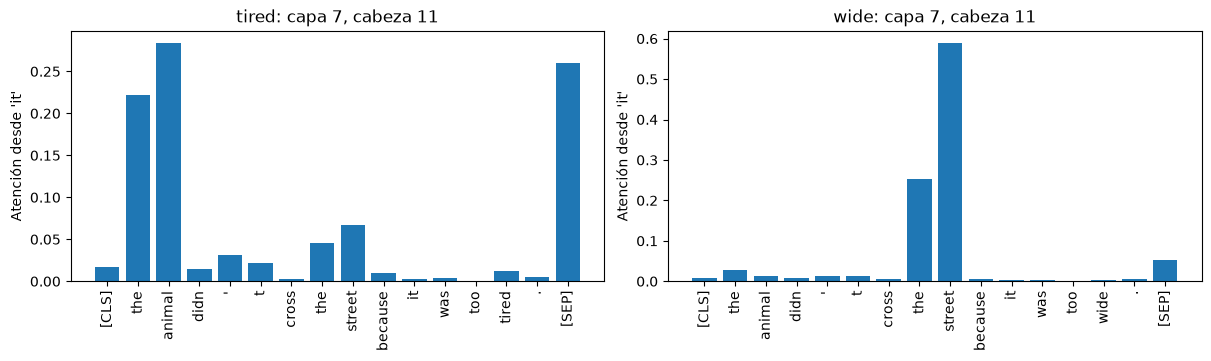

In [9]:
if len(coincidencias):
    mejor = coincidencias.iloc[0]
    capa, cabeza = int(mejor["capa"]) - 1, int(mejor["cabeza"]) - 1
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), constrained_layout=True)
    for ax, titulo, tokens, at, pos in [
        (axes[0], "tired", tokens_tired, at_tired, pos_t),
        (axes[1], "wide", tokens_wide, at_wide, pos_w),
    ]:
        pesos_it = at[capa, cabeza, pos["it"]].numpy()
        ax.bar(range(len(tokens)), pesos_it)
        ax.set_xticks(range(len(tokens)), tokens, rotation=90)
        ax.set_ylabel("Atención desde 'it'")
        ax.set_title(f"{titulo}: capa {capa+1}, cabeza {cabeza+1}")
    plt.show()
else:
    print("No se encontró una cabeza que cambie en el sentido solicitado. Conviene reportarlo así.")

Sí encontré el cambio que pedían: 22 de las 144 cabezas cumplen el criterio. El caso más claro fue la capa 7, cabeza 11. Con *tired*, «it» puso más peso en «animal» (0.2843 frente a 0.0671); con *wide*, lo puso en «street» (0.5902 frente a 0.0119). Esto muestra un cambio de atención en esa cabeza, aunque por sí solo no dice cómo resolvió la referencia el modelo completo.

### **GPT-2: máscara causal y atención al primer token**

Peso máximo hacia el futuro: 0.00e+00
Matriz triangular inferior: True


,capa,% al primer token,% uniforme de referencia
0,1,26.150000,19.12
1,2,45.919998,19.12
2,3,41.509998,19.12
3,4,52.889999,19.12
4,5,60.650002,19.12
5,6,77.129997,19.12
6,7,70.269997,19.12
7,8,81.580002,19.12
8,9,75.019997,19.12
9,10,84.559998,19.12


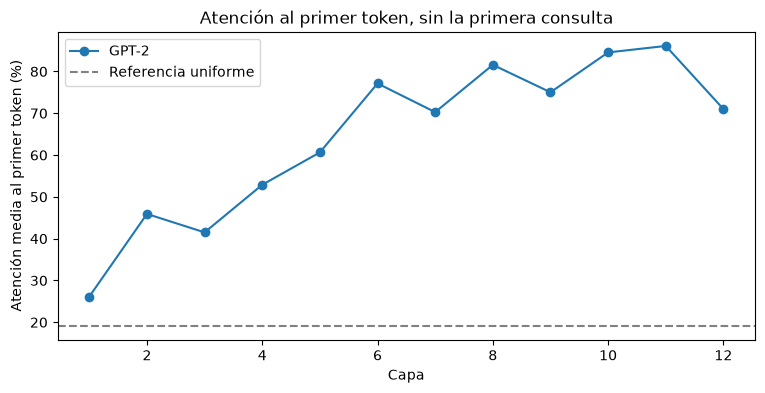

In [10]:
n_gpt2 = len(tokens_gpt2)
futuro = torch.triu(at_gpt2, diagonal=1)
max_futuro = float(futuro.max())
print(f"Peso máximo hacia el futuro: {max_futuro:.2e}")
print("Matriz triangular inferior:", bool(torch.all(futuro < 1e-6)))
assert torch.all(futuro < 1e-6)

proporcion_primero = at_gpt2[:, :, 1:, 0].mean(dim=(1, 2)).numpy()
base_uniforme = np.mean([1 / (i + 1) for i in range(1, n_gpt2)])
tabla_primero = pd.DataFrame({
    "capa": np.arange(1, len(proporcion_primero) + 1),
    "% al primer token": 100 * proporcion_primero,
    "% uniforme de referencia": 100 * base_uniforme,
})
display(tabla_primero.round(2))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla_primero["capa"], tabla_primero["% al primer token"], marker="o", label="GPT-2")
ax.axhline(100 * base_uniforme, color="gray", linestyle="--", label="Referencia uniforme")
ax.set(xlabel="Capa", ylabel="Atención media al primer token (%)",
       title="Atención al primer token, sin la primera consulta")
ax.legend()
plt.show()

El primer token recibió más atención que la referencia uniforme en todas las capas. La proporción estuvo entre 26 % y 86 %, mientras que la referencia era de 19 %. Esto se parece al patrón de *attention sinks* que describen Xiao et al. [12], aunque aquí solo lo probé con una oración.

### **Entropía de atención por capa**

Una entropía más alta significa que la atención está más repartida entre los tokens. Para comparar BERT y GPT-2 también tomo en cuenta cuántas posiciones puede consultar cada uno.

,capa,BERT H,BERT H normalizada,GPT-2 H,GPT-2 H normalizada
0,1,2.017,0.764,1.138,0.665
1,2,1.659,0.629,1.221,0.693
2,3,1.506,0.571,1.162,0.671
3,4,1.624,0.615,0.913,0.531
4,5,1.401,0.531,0.745,0.429
5,6,1.180,0.447,0.661,0.374
6,7,1.271,0.482,0.829,0.477
7,8,1.090,0.413,0.578,0.329
8,9,1.348,0.511,0.749,0.427
9,10,1.496,0.567,0.513,0.295


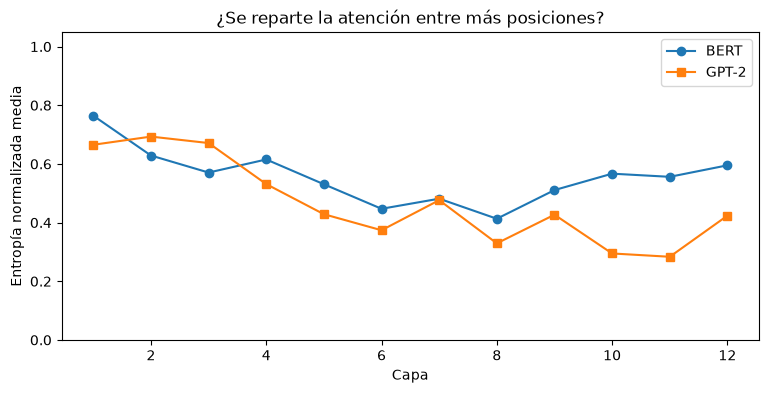

BERT: última capa menos primera = -0.169; más concentrada entre esos extremos.
GPT-2: última capa menos primera = -0.242; más concentrada entre esos extremos.


In [11]:
def entropia_por_capa(atenciones, causal=False):
    p = atenciones.numpy()
    n = p.shape[-1]
    h = -(p * np.log(np.clip(p, 1e-12, 1))).sum(axis=-1)  # capas, cabezas, consultas
    disponibles = np.arange(1, n + 1) if causal else np.full(n, n)
    log_m = np.log(disponibles)
    validas = log_m > 0
    h_normalizada = h[..., validas] / log_m[validas]
    return h.mean(axis=(1, 2)), h_normalizada.mean(axis=(1, 2))

h_bert, hn_bert = entropia_por_capa(at_bert)
h_gpt2, hn_gpt2 = entropia_por_capa(at_gpt2, causal=True)
tabla_entropia = pd.DataFrame({
    "capa": np.arange(1, len(h_bert) + 1),
    "BERT H": h_bert, "BERT H normalizada": hn_bert,
    "GPT-2 H": h_gpt2, "GPT-2 H normalizada": hn_gpt2,
})
display(tabla_entropia.round(3))
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(tabla_entropia["capa"], hn_bert, marker="o", label="BERT")
ax.plot(tabla_entropia["capa"], hn_gpt2, marker="s", label="GPT-2")
ax.set(xlabel="Capa", ylabel="Entropía normalizada media", ylim=(0, 1.05),
       title="¿Se reparte la atención entre más posiciones?")
ax.legend()
plt.show()
for nombre, valores in [("BERT", hn_bert), ("GPT-2", hn_gpt2)]:
    cambio = valores[-1] - valores[0]
    tendencia = "más difusa" if cambio > 0.02 else "más concentrada" if cambio < -0.02 else "sin cambio claro"
    print(f"{nombre}: última capa menos primera = {cambio:+.3f}; {tendencia} entre esos extremos.")

En los dos modelos, la última capa terminó con menor entropía que la primera. BERT bajó de 0.764 a 0.595 y GPT-2 de 0.665 a 0.424. Para esta oración, eso significa que al final la atención está más concentrada, aunque entre una capa y otra sí hay algunas subidas.

## **7. Discusión y análisis**

**¿Por qué permitió escalar los modelos?** En una RNN, el estado de un paso depende del anterior y limita el paralelismo a lo largo de la secuencia. La self-attention calcula muchas interacciones mediante operaciones matriciales paralelas y conecta directamente dos tokens cualesquiera en una capa. Eso facilita entrenar modelos grandes en aceleradores. El límite importante es el costo cuadrático en longitud: escalar la cantidad de parámetros no hace gratis procesar contextos largos [3].

**¿Se especializan las cabezas?** Los cuatro mapas y la tabla de patrones permiten buscar preferencias distintas, por ejemplo, hacia el token anterior, la puntuación o [CLS]. Si aparecen diferencias, son evidencia de comportamiento distinto en esta muestra. La comparación de «it» aporta un criterio más específico y cuantificado. No se puede concluir de aquí que todas las cabezas sean indispensables: para eso habría que medir la pérdida de desempeño al eliminar o intervenir cabezas en una tarea concreta.

**¿Los pesos explican decisiones?** Un mapa muestra por dónde pasó información en una operación de atención, pero la salida también depende de los vectores de valor, residuales, MLP y capas posteriores. Jain y Wallace muestran que pesos aparentemente interpretables pueden no corresponder con la importancia causal de las palabras [13]. Wiegreffe y Pinter argumentan que la utilidad explicativa depende de qué se entienda por explicación y cómo se pruebe [14]. Por eso usaría estos mapas como una pista para formular hipótesis, y contrastaría una hipótesis causal con intervenciones o ablaciones; no los presentaría como prueba de por qué el modelo decidió algo.

**¿Cuándo preferiría una RNN o CNN?** Una RNN puede convenir para una señal que llega paso a paso y requiere estado pequeño y latencia/memoria controladas. Una CNN puede ser suficiente cuando dominan patrones locales y interesa una implementación compacta. La decisión depende de datos, longitud, hardware y calidad exigida; no hay una arquitectura mejor para todo.

**¿Qué pasa con 100,000 tokens?** Una sola matriz de atención tendría diez mil millones de valores y ocuparía unos 40 GB en precisión de 32 bits, antes de multiplicar por cabezas, capas, batch y otros tensores. Consideraría FlashAttention para reducir memoria intermedia sin cambiar la atención, y ventanas, atención dispersa o resúmenes jerárquicos si acepto limitar o reorganizar conexiones. La opción adecuada depende de si necesito recuperar relaciones arbitrarias entre posiciones distantes [5, 6].

### **Conclusión**

La atención reemplaza el resumen fijo de seq2seq por una consulta a los estados relevantes y, en el Transformer, permite procesar posiciones en paralelo. Los mapas de BERT y GPT-2 ayudan a ver diferencias entre atención bidireccional y causal, y las medidas de entropía y atención al primer token permiten describir patrones sin depender solo del color de una gráfica. Para interpretar una decisión concreta, los pesos son un punto de partida que necesita pruebas adicionales.

## **Referencias**

1. Bahdanau, D., Cho, K. y Bengio, Y. (2015). [*Neural Machine Translation by Jointly Learning to Align and Translate*](https://arxiv.org/abs/1409.0473).
2. Luong, M.-T., Pham, H. y Manning, C. D. (2015). [*Effective Approaches to Attention-based Neural Machine Translation*](https://arxiv.org/abs/1508.04025).
3. Vaswani, A. et al. (2017). [*Attention Is All You Need*](https://arxiv.org/abs/1706.03762).
4. Su, J. et al. (2021). [*RoFormer: Enhanced Transformer with Rotary Position Embedding*](https://arxiv.org/abs/2104.09864).
5. Dao, T. et al. (2022). [*FlashAttention: Fast and Memory-Efficient Exact Attention with IO-Awareness*](https://arxiv.org/abs/2205.14135).
6. Beltagy, I., Peters, M. E. y Cohan, A. (2020). [*Longformer: The Long-Document Transformer*](https://arxiv.org/abs/2004.05150).
7. PyTorch. [scaled_dot_product_attention](https://docs.pytorch.org/docs/stable/generated/torch.nn.functional.scaled_dot_product_attention.html).
8. PyTorch. [MultiheadAttention](https://docs.pytorch.org/docs/stable/generated/torch.nn.MultiheadAttention.html).
9. PyTorch. [TransformerEncoderLayer](https://docs.pytorch.org/docs/stable/generated/torch.nn.TransformerEncoderLayer.html).
10. PyTorch. [Transformer](https://docs.pytorch.org/docs/stable/generated/torch.nn.Transformer.html).
11. Hugging Face. [Model outputs y attentions](https://huggingface.co/docs/transformers/main_classes/output).
12. Xiao, G. et al. (2023). [*Efficient Streaming Language Models with Attention Sinks*](https://arxiv.org/abs/2309.17453).
13. Jain, S. y Wallace, B. C. (2019). [*Attention is not Explanation*](https://arxiv.org/abs/1902.10186).
14. Wiegreffe, S. y Pinter, Y. (2019). [*Attention is not not Explanation*](https://arxiv.org/abs/1908.04626).